<a href="https://colab.research.google.com/github/jinminji0314/mj/blob/main/hw02.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 과제 2: 내 사진으로 재활용품 분류기 만들기

## 과제 안내

실습 7에서는 개미·벌 사진 244장으로 사전학습 모델의 분류부를 학습시켰습니다. 이번에는 사진을 **직접 찍어서** 재활용품 세 종류를 가르는 분류기를 만듭니다.

| 클래스 | 폴더 이름 | 예 |
|---|---|---|
| 캔 | `can` | 음료 캔, 통조림 캔 |
| 종이팩 | `carton` | 우유팩, 두유·주스 종이팩 |
| 페트병 | `pet` | 생수병, 음료 페트병 |

채점은 교수가 따로 찍어 둔 **비공개 테스트 사진** 97장으로 합니다. 사진은 공개하지 않지만, 8절에서 내 가중치 파일의 최종 테스트 정확도와 클래스별 정확도를 미리 확인할 수 있습니다(하루 다섯 번). 테스트 사진은 실내와 실외의 여러 장소에서 찍었고, 손에 든 것, 바닥이나 탁자에 놓은 것, 멀리서 찍어 작게 나온 것, 위에서 내려다본 것, 찌그러진 것, 라벨을 뗀 것이 섞여 있습니다. 같은 클래스 안에서도 상표와 모양이 여러 가지입니다. 그러므로 내 사진도 여러 물건을 여러 조건에서 찍어야 테스트 사진을 맞힐 수 있습니다. 모델과 전처리는 모두 같으므로, 점수는 사진을 어떻게 모았는지와 어떻게 학습시켰는지에서 갈립니다.

테스트 사진에는 한 장에 물건이 하나만 나옵니다. 유리병, 종이컵, 플라스틱 용기, 음료 파우치는 나오지 않습니다.

다음은 테스트 사진과 같은 조건에서 찍은 예시 사진입니다.

![](https://ralbu85.github.io/lecture_deeplearning/assets/img/hw02_examples.jpg)

**대응 실습:** [실습 7 사전학습 모델로 사진 판별하기](https://ralbu85.github.io/lecture_deeplearning/labs/lab07.html). 실습 7의 코드를 옆에 열어 두고 진행합니다.

**Colab 설정:** 메뉴 **런타임 → 런타임 유형 변경 → T4 GPU**를 고른 뒤 시작합니다.

### 사진 찍기와 올리기

1. 휴대폰으로 클래스마다 사진을 찍습니다. 장수 제한은 없습니다.
   쓰레기를 뒤질 필요는 없습니다. 냉장고나 편의점에 있는 음료 캔, 페트병, 우유팩을 찍어도 되고, 마신 뒤 헹군 것을 찌그러뜨리거나 라벨을 떼어 찍어도 됩니다.
2. 구글 드라이브의 `내 드라이브`에 `hw02` 폴더를 만들고, 그 안에 `can`, `carton`, `pet` 폴더를 만들어 사진을 넣습니다. 폴더 이름은 영어 그대로 씁니다.
3. 직접 찍은 사진만 씁니다. 인터넷에서 내려받은 사진이나 다른 학생의 사진은 쓰지 않습니다. 채점할 때 사진의 촬영 정보와 학생 사이의 같은 사진을 확인합니다.

```
내 드라이브/hw02/
  can/      캔 사진
  carton/   종이팩 사진
  pet/      페트병 사진
```

### 제출 규칙

1. 아래 첫 셀의 `STUDENT_ID`와 `NAME`을 본인 것으로 바꿉니다.
2. `____`를 모두 채운 뒤 **런타임 다시 시작 후 전체 실행**으로 위에서부터 끝까지 오류 없이 실행합니다.
3. 변수 이름과 함수 이름은 바꾸지 않습니다.
4. 마지막 "제출 전 확인" 셀이 `통과`를 출력하는지 확인합니다.
5. 아래 파일 세 개를 제출합니다. 앞의 두 개는 7절의 셀이 만들어 내려받게 해 줍니다.

| 파일 | 내용 |
|---|---|
| `hw02_학번.pt` | 학습한 분류부의 가중치 |
| `hw02_학번_photos.zip` | 학습에 쓴 사진 (크기를 줄인 것) |
| `hw02_학번.ipynb` | 출력이 포함된 노트북 (파일 → 다운로드 → .ipynb) |

6. 개인 과제이므로 다른 학생의 가중치 파일이나 사진을 받아서 내지 않습니다. 가중치는 내가 찍은 사진으로만 학습하고, 가중치 숫자를 직접 고치지 않습니다. 채점할 때 학생끼리 가중치를 비교하고, 제출한 가중치가 제출한 사진으로 학습한 것인지 확인합니다.

### 채점 (100점)

| 항목 | 배점 |
|---|---:|
| 비공개 테스트 사진의 정확도 | 70 |
| 가중치 파일이 정해진 모델에 그대로 들어가는가 | 10 |
| 사진 zip에 세 클래스의 사진이 모두 있는가 | 10 |
| 노트북의 빈칸을 모두 채우고 끝까지 실행했는가 | 10 |

정확도 점수는 다음과 같습니다.

| 테스트 정확도 | 80% 이상 | 70% 이상 | 60% 이상 | 50% 이상 | 40% 이상 | 40% 미만 |
|---|---:|---:|---:|---:|---:|---:|
| 점수 | 70 | 60 | 50 | 40 | 30 | 20 |

In [1]:
# Colab 준비
!pip -q install pillow-heif

In [2]:
STUDENT_ID = "202312006"   # 본인 학번으로 바꿉니다
NAME = "진민지"            # 본인 이름으로 바꿉니다

## 1. 준비 — 제공 코드

In [3]:
# ▶ 그대로 실행하세요 — 준비
import torch

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.manual_seed(42)
print(device)

cuda


Colab에서 GPU 런타임이면 `cuda`가 나옵니다.

## 2. 사진 가져오기 — 제공 코드

휴대폰 사진은 크기가 커서 그대로 학습하면 느리고, 아이폰 사진(HEIC)은 바로 열리지 않습니다. 그래서 드라이브의 사진을 짧은 변 256으로 줄여 Colab 안으로 복사합니다. 이때 클래스마다 사진의 5분의 1을 검증용으로 따로 떼어 둡니다.

In [18]:
# ▶ 그대로 실행하세요 — 구글 드라이브 연결
from google.colab import drive

drive.mount('/content/drive')
PHOTO_DIR = '/content/drive/MyDrive/hw02'

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [19]:
import shutil
shutil.rmtree('hw02_data', ignore_errors=True)

In [20]:
# ▶ 그대로 실행하세요 — 사진을 줄여서 훈련용과 검증용으로 나누기
import os, csv, random, unicodedata
from PIL import Image, ImageOps
from pillow_heif import register_heif_opener

register_heif_opener()          # 아이폰 사진(HEIC)도 열 수 있게 한다

CLASSES = ['can', 'carton', 'pet']
DATA = './hw02_data'
random.seed(42)
rows = []
for c in CLASSES:
    src = os.path.join(PHOTO_DIR, c)
    assert os.path.isdir(src), f'{src} 폴더가 없습니다. 드라이브의 폴더 이름을 확인하세요.'
    names = sorted(n for n in os.listdir(src) if not n.startswith('.'))
    assert len(names) >= 5, f'{c} 폴더에 사진이 5장 이상 있어야 합니다.'
    random.shuffle(names)
    n_val = len(names) // 5     # 클래스마다 5분의 1은 검증용
    for split in ['train', 'val']:
        os.makedirs(os.path.join(DATA, split, c), exist_ok=True)
    for k, name in enumerate(names):
        try:
            img = Image.open(os.path.join(src, name))
        except Exception:
            print('사진이 아니라서 건너뜁니다:', c, name)
            continue
        exif = img.getexif()                         # 촬영 정보 (271은 제조사, 272는 기종)
        img = ImageOps.exif_transpose(img).convert('RGB')   # 찍은 방향대로 세우고 RGB 세 채널로 맞춘다
        w, h = img.size
        scale = 256 / min(w, h)                      # 짧은 변이 256이 되도록 줄인다
        img = img.resize((round(w * scale), round(h * scale)))
        split = 'val' if k < n_val else 'train'
        file = f'{c}_{k:04d}.jpg'
        img.save(os.path.join(DATA, split, c, file), quality=90)
        rows.append([split, c, file, unicodedata.normalize('NFC', name),
                     str(exif.get(271, '')), str(exif.get(272, ''))])

# 어떤 원본 사진을 어디에 넣었는지 기록해 둔다 (사진 zip에 함께 들어간다)
with open(os.path.join(DATA, 'manifest.csv'), 'w', newline='') as f:
    csv.writer(f).writerows([['split', 'class', 'file', 'original', 'maker', 'model']] + rows)

for split in ['train', 'val']:
    print(split, {c: len(os.listdir(os.path.join(DATA, split, c))) for c in CLASSES})

train {'can': 21, 'carton': 8, 'pet': 25}
val {'can': 5, 'carton': 1, 'pet': 6}


클래스마다 훈련용과 검증용 사진 수가 나옵니다.

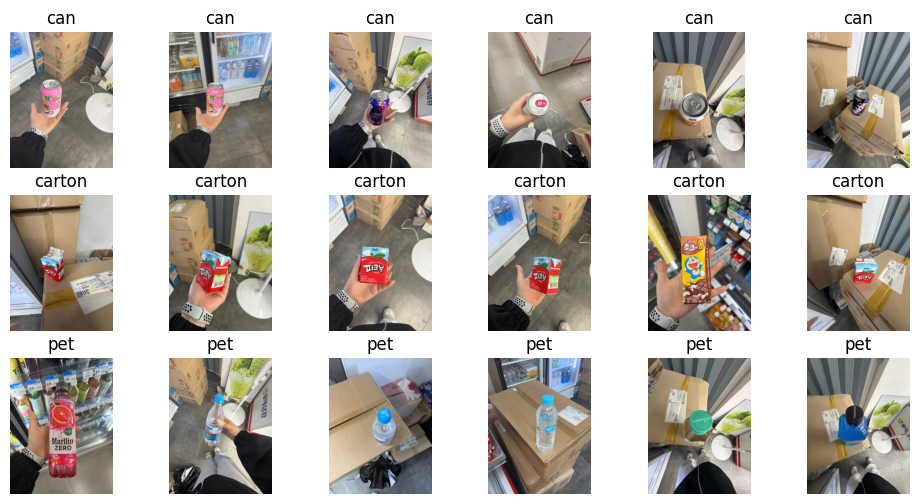

In [21]:
# ▶ 그대로 실행하세요 — 클래스마다 훈련 사진 여섯 장 보기
import matplotlib.pyplot as plt

fig, axes = plt.subplots(3, 6, figsize=(12, 6))
for row, c in zip(axes, CLASSES):
    files = sorted(os.listdir(os.path.join(DATA, 'train', c)))[:6]
    for ax, file in zip(row, files):
        ax.imshow(Image.open(os.path.join(DATA, 'train', c, file)))
        ax.set_title(c)
    for ax in row:
        ax.axis('off')
plt.show()

## 3. 전처리와 데이터 로더

채점기는 아래 `tf`로 테스트 사진을 전처리합니다. 그러므로 검증 사진에도 같은 전처리를 써야 합니다. 이 셀은 바꾸지 않습니다.

In [22]:
# ▶ 그대로 실행하세요 — 채점기와 같은 전처리 (바꾸지 않습니다)
from torchvision import transforms

mean = (0.485, 0.456, 0.406)   # ImageNet 사진의 채널별(R, G, B) 평균
std = (0.229, 0.224, 0.225)    # ImageNet 사진의 채널별(R, G, B) 표준편차
tf = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])

### 3.1 훈련용 전처리 — 채워 넣기 ①

훈련 사진에는 증강을 넣습니다. 어떤 증강을 얼마나 넣을지는 직접 정합니다. 테스트 사진이 어떤 조건에서 찍혔는지 생각해서 고릅니다. 크기는 `tf`와 같이 224×224로 맞추고, 맨 끝은 `ToTensor()`와 `Normalize(mean, std)`로 끝냅니다.

In [23]:
# ✏️ 직접 채워 보세요
tf_train = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

### 3.2 데이터셋과 로더 — 채워 넣기 ②

훈련 사진에는 `tf_train`을, 검증 사진에는 `tf`를 씁니다. 훈련 로더는 에폭마다 순서를 섞습니다.

In [24]:
# ✏️ 직접 채워 보세요
from torchvision import datasets
from torch.utils.data import DataLoader

train_ds = datasets.ImageFolder(DATA + '/train', transform=tf_train)
val_ds = datasets.ImageFolder(DATA + '/val', transform=tf)

train_loader = DataLoader(train_ds, batch_size=32, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=64)
print(train_ds.classes, len(train_ds), len(val_ds))

['can', 'carton', 'pet'] 54 12


`['can', 'carton', 'pet']`과 훈련·검증 사진 수가 나와야 합니다.

## 4. 모델 — 채워 넣기 ③

실습 7과 같이 ImageNet으로 학습한 ResNet-18을 불러와 모든 파라미터를 동결하고, 분류부를 출력 3개짜리로 바꿉니다. 채점기도 같은 모델에 여러분의 분류부를 넣어 채점합니다.

In [25]:
# ✏️ 직접 채워 보세요
from torchvision import models
import torch.nn as nn

weights = models.ResNet18_Weights.IMAGENET1K_V1
model = models.resnet18(weights=weights)
for p in model.parameters():
    p.requires_grad = False
model.fc = nn.Linear(512, 3)
model = model.to(device)

n_train = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(n_train)

1539


학습할 파라미터는 `1539`개여야 합니다.

## 5. 학습

### 5.1 학습 함수와 평가 함수 — 제공 코드

실습 7과 같은 함수입니다.

In [26]:
# ▶ 그대로 실행하세요 — 학습 함수와 평가 함수
# 한 에폭 동안 학습하고, 평균 손실을 돌려준다
def train_one_epoch(model, loader, criterion, optimizer):
    model.train()
    total = 0.0
    n = 0
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        loss = criterion(model(xb), yb)
        loss.backward()
        optimizer.step()
        total += loss.item() * len(yb)
        n += len(yb)
    return total / n

# 학습 없이 평균 손실과 정확도를 잰다
def evaluate(model, loader, criterion):
    model.eval()
    total = 0.0
    correct = 0
    n = 0
    with torch.no_grad():
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            out = model(xb)
            total += criterion(out, yb).item() * len(yb)
            correct += (out.argmax(1) == yb).sum().item()
            n += len(yb)
    return total / n, correct / n

### 5.2 학습 — 채워 넣기 ④

옵티마이저에는 학습할 분류부의 파라미터만 넘깁니다. 에폭 수는 검증 정확도를 보면서 직접 정합니다. 훈련 사진이 48장이면 32장씩 두 묶음이라, 한 에폭에 가중치를 두 번만 고칩니다. 그러므로 사진이 적을수록 에폭을 늘려야 하고, 검증 정확도가 더 오르지 않을 때까지 늘립니다.

In [27]:
# ✏️ 직접 채워 보세요
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.fc.parameters(), lr=0.001)

EPOCHS = 30
history = []
for epoch in range(EPOCHS):
    train_one_epoch(model, train_loader, criterion, optimizer)
    val_loss, val_acc = evaluate(model, val_loader, criterion)
    history.append(val_acc)
    print(epoch, round(val_loss, 4), round(val_acc, 4))

0 0.8053 0.5833
1 0.8011 0.5833
2 0.7447 0.6667
3 0.7074 0.75
4 0.6812 0.8333
5 0.679 0.8333
6 0.7011 0.8333
7 0.7228 0.75
8 0.7212 0.75
9 0.6907 0.75
10 0.6443 0.75
11 0.6188 0.8333
12 0.6088 0.8333
13 0.599 0.8333
14 0.5911 0.8333
15 0.587 0.8333
16 0.5895 0.75
17 0.5884 0.75
18 0.5772 0.75
19 0.5699 0.8333
20 0.5575 0.8333
21 0.5499 0.8333
22 0.5425 0.8333
23 0.5365 0.8333
24 0.531 0.8333
25 0.5278 0.8333
26 0.5284 0.8333
27 0.5276 0.8333
28 0.5271 0.8333
29 0.5199 0.8333


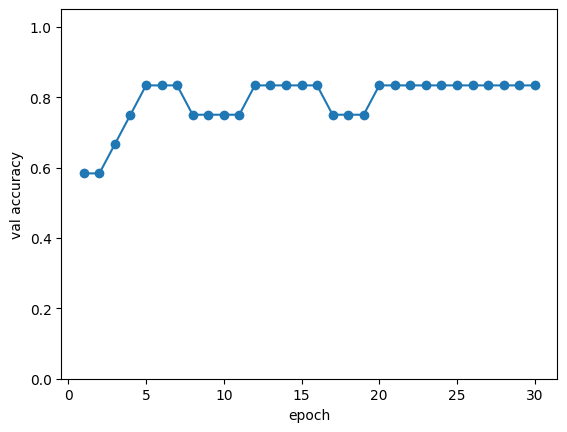

In [28]:
# ▶ 그대로 실행하세요 — 검증 정확도 그래프
plt.plot(range(1, len(history) + 1), history, marker='o')
plt.xlabel('epoch')
plt.ylabel('val accuracy')
plt.ylim(0, 1.05)
plt.show()

## 6. 틀린 검증 사진 보기 — 제공 코드

틀린 사진을 보면 어떤 조건의 사진이 부족한지 알 수 있습니다. 사진을 더 찍어 드라이브에 넣었으면 2절부터 다시 실행합니다.

틀린 사진 2 / 12


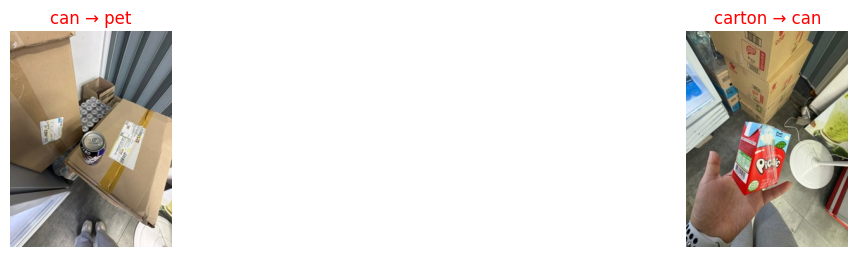

In [29]:
# ▶ 그대로 실행하세요 — 틀린 검증 사진
raw_val = datasets.ImageFolder(DATA + '/val')
model.eval()
wrong = []
for i in range(len(raw_val)):
    img, label = raw_val[i]
    with torch.no_grad():
        p = model(tf(img).unsqueeze(0).to(device)).argmax(1).item()   # 판별한 클래스 번호
    if p != label:
        wrong.append((img, label, p))

print('틀린 사진', len(wrong), '/', len(raw_val))
if wrong:
    fig, axes = plt.subplots(1, min(len(wrong), 8), figsize=(16, 2.8), squeeze=False)
    for ax, (img, label, p) in zip(axes[0], wrong):
        ax.imshow(img)
        ax.set_title(f'{CLASSES[label]} → {CLASSES[p]}', color='red')   # 실제 → 판별
        ax.axis('off')
    plt.show()

## 7. 제출 파일 만들기 — 제공 코드

분류부의 가중치와 사진을 파일로 만들어 내려받습니다. 노트북은 메뉴 **파일 → 다운로드 → .ipynb**로 따로 내려받습니다.

In [30]:
# ▶ 그대로 실행하세요 — 제출 파일 만들기
import shutil
from google.colab import files

PT_FILE = f'hw02_{STUDENT_ID}.pt'
torch.save({'student_id': STUDENT_ID,
            'classes': train_ds.classes,
            'fc': {k: v.cpu() for k, v in model.fc.state_dict().items()}}, PT_FILE)
ZIP_FILE = shutil.make_archive(f'hw02_{STUDENT_ID}_photos', 'zip', DATA)

files.download(PT_FILE)
files.download(ZIP_FILE)
print(PT_FILE, ZIP_FILE)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

hw02_202312006.pt /content/hw02_202312006_photos.zip


## 8. 최종 테스트 정확도 확인 — 제공 코드

7절에서 만든 가중치 파일의 숫자(분류부 가중치 3×512개와 편향 3개)와 학번을 교수의 점수 확인 서버로 보내, 비공개 테스트 사진 97장의 정확도를 확인합니다. 테스트 사진과 정답은 그 서버에만 있고, 이 노트북에는 정확도와 점수, 클래스별 정확도만 돌아옵니다. 채점도 같은 사진으로 같은 계산을 하므로, 확인한 파일을 그대로 내면 여기서 본 정확도가 최종 정확도입니다.

학번 하나당 하루 다섯 번 확인할 수 있습니다. 정확도가 낮은 클래스가 있으면 그 클래스를 여러 물건, 여러 장소, 여러 거리와 각도에서 더 찍어 드라이브에 넣고 2절부터 다시 실행합니다.

In [31]:
# ▶ 그대로 실행하세요 — 최종 테스트 정확도 확인
import requests
from IPython.display import Markdown, display

saved = torch.load(PT_FILE, weights_only=True)      # 7절에서 만든 가중치 파일을 다시 읽는다
payload = {'student_id': saved['student_id'], 'classes': saved['classes'], 'file': PT_FILE,
           'weight': saved['fc']['weight'].tolist(),   # 분류부 가중치 3×512개
           'bias': saved['fc']['bias'].tolist()}       # 편향 3개
r = requests.post('https://dllecture.tailcce2b.ts.net/hw02-check', json=payload, timeout=60)
display(Markdown(r.text))

### 학번 202312006 — 최종 테스트 정확도 63.9% (62 / 97장)

이 가중치 파일을 그대로 내면 정확도 점수는 **50점**입니다 (70점 만점).

| 클래스 | 맞힌 사진 | 정확도 |
|---|---:|---:|
| 캔 (`can`) | 29 / 33 | 88% |
| 종이팩 (`carton`) | 12 / 33 | 36% |
| 페트병 (`pet`) | 21 / 31 | 68% |

오늘 확인한 횟수: 2 / 5

## 제출 전 확인 — 제공 코드

아래 셀이 `통과`를 출력해야 합니다. 오류가 나면 해당 항목을 다시 확인합니다.

In [ ]:
# ▶ 그대로 실행하세요 — 제출 전 확인
assert STUDENT_ID != "20240000" and NAME != "홍길동", "학번과 이름을 바꾸세요"
assert train_ds.classes == CLASSES, "클래스 폴더 이름을 확인하세요"
assert n_train == 1539 and model.fc.out_features == 3, "동결과 분류부 교체를 확인하세요"
assert len(history) == EPOCHS, "학습을 끝까지 실행하세요"
assert os.path.exists(PT_FILE) and os.path.exists(ZIP_FILE), "7절의 제출 파일 만들기를 실행하세요"
saved = torch.load(PT_FILE, weights_only=True)   # 채점기와 같은 방법으로 가중치 파일을 다시 읽는다
assert saved['classes'] == CLASSES and tuple(saved['fc']['weight'].shape) == (3, 512), "7절의 제출 파일 만들기를 다시 실행하세요"
print("통과")